In [18]:
import pickle
import warnings

warnings.filterwarnings('ignore')

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import wandb

import myutils


In [19]:
workspace,experiment=myutils.workspace()

IS_FINE_TUNED = True

run = "ms-Sep09-14-28"
# run = "ms-Sep09-14-13"
# run = "ms-Sep03-14-24"
# run = "pred_ms-Sep17-11-12"
pred = 'fine-tuned' if IS_FINE_TUNED else 'wo-fine-tuning'
pred_dir = experiment / f'predictions/{pred}/{run}'
save_dir = experiment / f'save/dev_{run}' if IS_FINE_TUNED else pred_dir
pred_file = pred_dir/'pred_ms.h5ad'

data_dir = experiment/"scGPT/data/ms"
assert pred_dir.exists()

In [20]:

path = save_dir / "results.pkl"
print(path)
print(path.exists())
print(path.stat().st_size if path.exists() else "missing")

/omics/odcf/analysis/OE0290_projects/heroes-aya_pools/AG_Thongjuea/Code/10x_multiomics/Selina/project/experiment03-scGPT/save/dev_ms-Sep09-14-28/results.pkl
True
216358


In [21]:
with open(save_dir / 'results.pkl', 'rb') as f:
    results = pickle.load(f)
id2type = results['id_maps']
predictions = results['predictions']
labels = results['labels']
print(results.keys())
print()

if (pred_file.exists()):
    adata = sc.read(pred_file)
    print("PRED")
    print(adata)
else:
    pred_dir.mkdir(parents=True, exist_ok=True)
    adata = sc.read(data_dir / "filtered_ms_adata.h5ad")
    adata.var.set_index(adata.var["gene_name"], inplace=True)
    adata.obs["predictions"] = [id2type[p] for p in predictions]
    print("DEV")
    print(adata)

celltypes = adata.obs["celltype"].unique()
celltypes = list(celltypes)

dict_keys(['predictions', 'labels', 'results', 'id_maps'])

DEV
AnnData object with n_obs × n_vars = 13468 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause

In [22]:
from collections import Counter

Counter(predictions)

Counter({6: 2103,
         7: 1507,
         8: 1492,
         3: 1405,
         4: 1378,
         13: 1185,
         15: 804,
         0: 788,
         17: 786,
         5: 545,
         12: 541,
         1: 291,
         9: 271,
         2: 212,
         11: 93,
         10: 67})

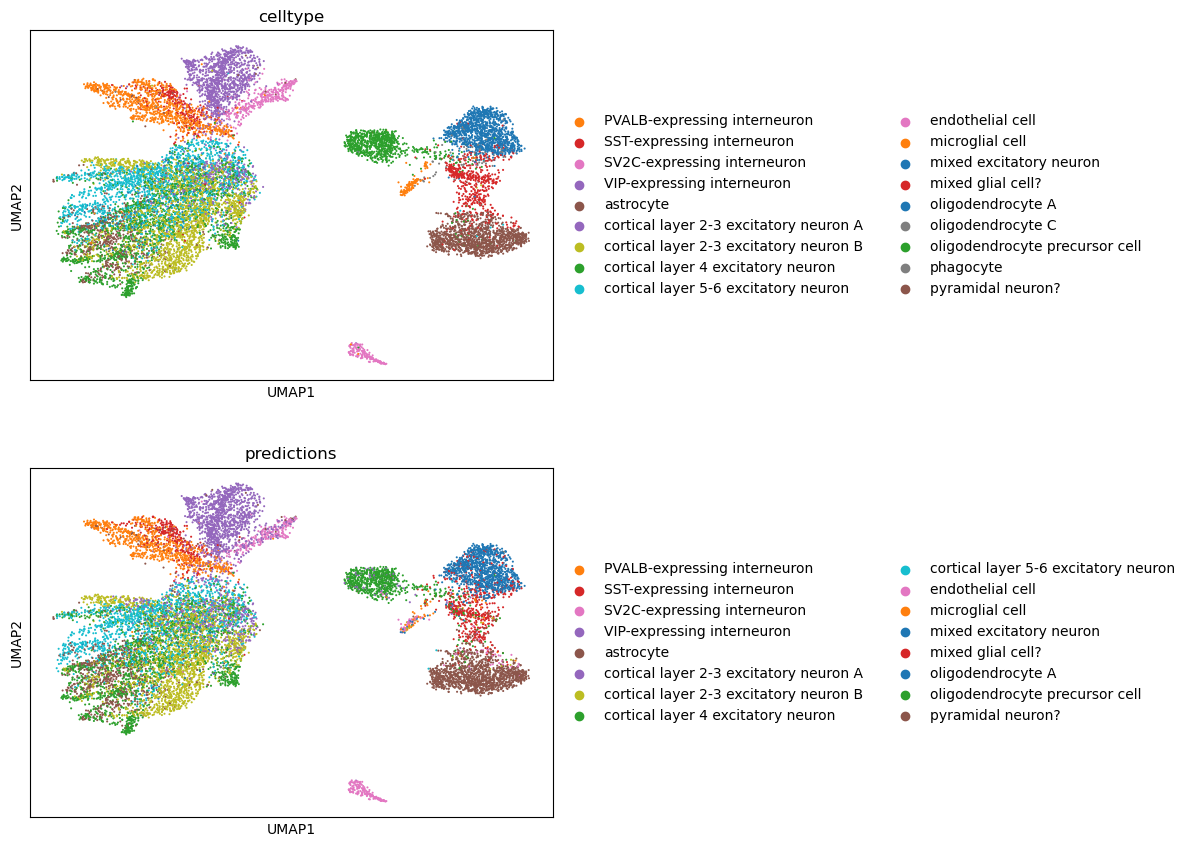

In [23]:
palette_ = plt.rcParams["axes.prop_cycle"].by_key()["color"] 
palette_ = plt.rcParams["axes.prop_cycle"].by_key()["color"] + plt.rcParams["axes.prop_cycle"].by_key()["color"] + plt.rcParams["axes.prop_cycle"].by_key()["color"]
palette_ = {c: palette_[i] for i, c in enumerate(celltypes)}


sc.pl.umap(
        adata,
        color=["celltype", "predictions"],
        palette=palette_,
        ncols=1,
        show=False
    )
plt.savefig(pred_dir / "results.png", dpi=300, bbox_inches="tight")

In [24]:
from sklearn.metrics import confusion_matrix

celltypes = [id2type[i] for i in range(len(celltypes))]
for i in set([id2type[p] for p in predictions]):
    if i not in celltypes:
        celltypes.remove(i)
cm = confusion_matrix(labels, predictions)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])

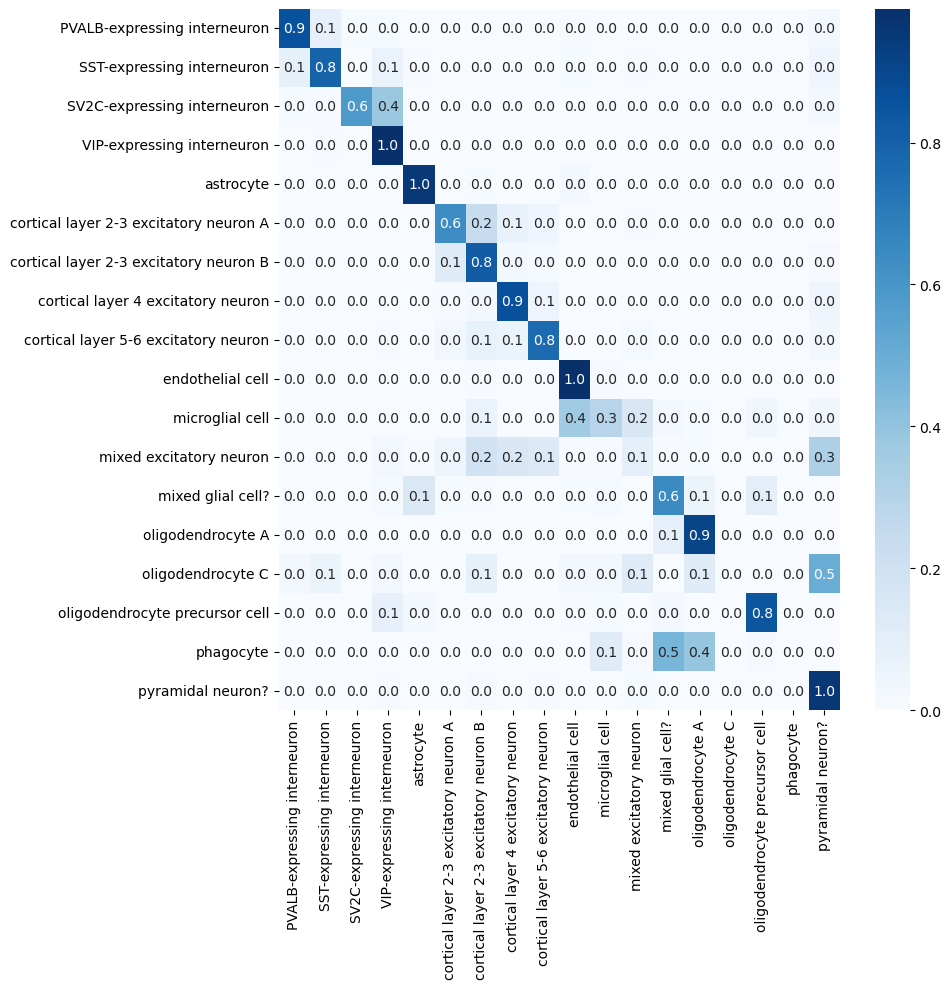

In [25]:
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt=".1f", cmap="Blues")
plt.tight_layout()
plt.savefig(pred_dir / "confusion_matrix.png", dpi=300, )

results["test/confusion_matrix"] = wandb.Image(
    str(pred_dir / "confusion_matrix.png"),
    caption=f"confusion matrix",
)
